In [1]:
try:
    import idi
except ImportError:
    print("IDI not installed. Installing...")
    %pip install -q git+https://github.com/fzimmermann89/idi
    import idi

/home/zimmf/idi/ipynb/idi/__init__.py:3: UserWarning: mkl autocorrelate 3d not compiled. using numpy fft
  from . import simulation, reconstruction, util


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
import h5py
from tqdm import tqdm

%matplotlib inline

## Settings

In [22]:
excitation = 1e7  # emitters per um^3
thickness = 4  # in um
focus_fwhm = (.250,.250)#(0.375, 0.170)  # in um
attenuation_length = np.inf  # in um
object_rotation_angles = np.array([0, 0, 70]) / 180 * np.pi  # rotates object in focus
# (np.float64(110.87563036889001),
#  np.float64(95.99788846793076),
#  np.float64(-75.48246181051542))
pixelsize = 75  # in um
detector_size = 256  # pixels
detector_distance = 48.3  # in cm

# detector_offset_y, detector_offset_x = [-200 * 75.0, -200 * 75.0]  # center up left
# # detector_offset_y, detector_offset_x=[ 66820.,-53480.] # top right
# # detector_offset_y, detector_offset_x=[-67050.,53020.]  # bottom left
beam = np.array((1101, 1149))
center = (392, 256)  # [-53175, -66975] μm
center = (942, 772) # [-11925, -28275] μm
center = (2041, 390) # [ 70500, -56925] μm
detector_offset_y, detector_offset_x = (center - beam) * pixelsize

detector_angles = (
    np.array([0, 0]) / 180 * np.pi
)  # rotates detector distance, for example for detector in 90 degree angle


n_img = 3  # number of images to simulate
E = 4950  # in ev
random_phase = True  # random phase for each emitter (idi)
random_positions = True  # random emitter positions in the object in each image
n_modes = 1  # number of overlaid modes due to coherence etc
n_photons = np.inf  # photons on the detector. # np.inf: no noise. # -1: calculate from geometry and excitation


outputpath = Path(
    f"output-{datetime.now().strftime('%Y-%m-%d-%H-%M-%S')}.h5"
)  # output filename

In [23]:
# change simobject to a different object if you want to simulate a different object
simobject = idi.simulation.simobj.foil(
    E=E,
    excitation=excitation,
    thickness=thickness,
    fwhm=focus_fwhm,
    attenuationlength=np.inf,
    rho=(2, 2),
    rotangles=object_rotation_angles,
)
simobject.rndPos = random_positions
simobject.rndPhase = random_phase

if n_photons == -1:
    n_photons = simobject.N * (
        (pixelsize * detector_size) ** 2 / (4 * np.pi * (detector_distance * 1e4) ** 2)
    )

print(
    f"{simobject.N:.2e} emitters in the object. {n_photons:.2e} photons on the detector."
)

2.83e+06 emitters in the object. inf photons on the detector.


#### Visualize Object

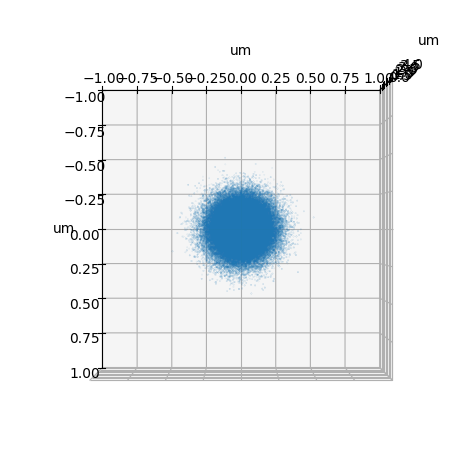

In [24]:
pos = simobject.get2()[0]
fig = plt.figure()
ax = plt.axes(projection="3d")
if len(pos) > 1e5:
    print("Warning: too many emitters to plot, randomly choosing subset")
    pos = pos[np.random.choice(len(pos), int(1e5), replace=False)]
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=0.01)
ax.set_xlabel("um")
ax.set_ylabel("um")
ax.set_zlabel("um")
ax.view_init(30, -80)
ax.view_init(90, 0)
plt.tight_layout()
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.show()

(np.float64(-0.5), np.float64(999.5), np.float64(999.5), np.float64(-0.5))

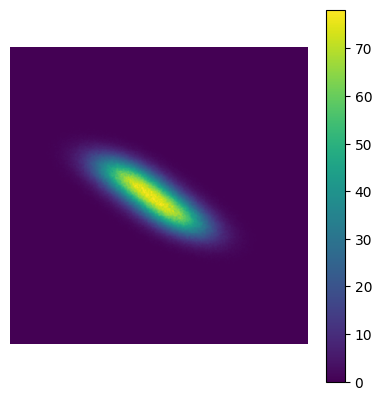

In [8]:
simobj2 = idi.simulation.simobj.foil(
    E=E,
    excitation=excitation,
    thickness=thickness,
    fwhm=focus_fwhm,
    attenuationlength=np.inf,
    rho=(2, 2),
    rotangles=object_rotation_angles,
)
simobj2.rndPos = True
simobj2.rndPhase = False
simobj2 = idi.simulation.simobj.fake_view_from_position(
    simobj2, detector_offset_x, detector_offset_y, detector_distance * 1e4
)
img = simobj2.getImg(0.002)


def pad(x, size):
    pad = [new - current for current, new in zip(x.shape, size)]
    pads = [(p // 2, p - p // 2) for p in pad]
    return np.pad(x, pads)


img = pad(np.abs(img), (1000, 1000))
from scipy.ndimage import gaussian_filter

img = gaussian_filter(img, 2)
plt.matshow(img)
plt.colorbar()
plt.axis("off")

In [25]:
cdi = idi.simulation.simple.simulate(
    simobj2, detector_size, pixelsize, detector_distance * 1e4, simobj2.k
)

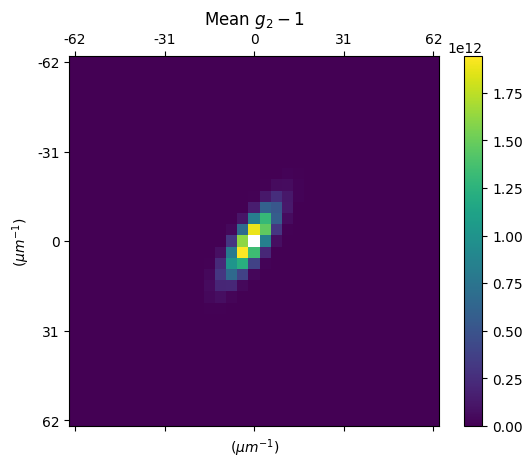

In [26]:
idi.util.plot_2d(
    np.abs(cdi) ** 2,
    mask_center=True,
    crop=(33, 33),
    E=E,
    detz=detector_distance * 1e4,
    pixelsize=pixelsize,
    title="Mean $g_2-1$",
    q_ticks=True,
    cmap="viridis",
);

## Simulation

In [27]:
with h5py.File(outputpath, "w") as file:
    file.attrs.update(
        {
            "excitation": excitation,
            "thickness": thickness,
            "focus_fwhm": focus_fwhm,
            "attenuation_length": attenuation_length,
            "object_rotation_angles": object_rotation_angles,
            "pixelsize": pixelsize,
            "detector_size": detector_size,
            "detector_distance": detector_distance,
            "detector_offset_x": detector_offset_x,
            "detector_offset_y": detector_offset_y,
            "detector_angles": detector_angles,
            "E": E,
            "random_phase": random_phase,
            "random_positions": random_positions,
            "n_modes": n_modes,
            "n_photons": n_img,
            "n_img": n_img,
        }
    )
    file["simobject_positions"] = simobject.get2()[0]
    dset_wavefield = file.create_dataset(
        "wavefields",
        shape=(1, detector_size, detector_size),
        maxshape=(None, detector_size, detector_size),
        chunks=(1, detector_size, detector_size),
        dtype=np.complex64,
    )

    correlator = idi.reconstruction.simple.correlator2d()
    generator = idi.simulation.auto.simulate_gen(
        simobject,
        detector_size,
        pixelsize,
        detector_distance * 1e4,
        detangles=detector_angles,
        detoffset=(detector_offset_x, detector_offset_y),
        returngpu=True,
        settings="single",
    )
    for i_img in tqdm(range(n_img)):
        photons = 0
        for i_mode in range(n_modes or 1):
            wavefield = next(generator)
            dset_wavefield.resize(
                ((len(dset_wavefield)) + 1, detector_size, detector_size)
            )
            dset_wavefield[-1] = (
                wavefield.astype(np.complex64)
                if isinstance(wavefield, np.ndarray)
                else wavefield.get().astype(np.complex64)
            )
            intensity = wavefield.real**2 + wavefield.imag**2
            photons = photons + idi.simulation.common.randomphotons(
                intensity, n_photons
            )
        correlator.add(photons)
    file["correlations_mean"] = correlator.mean
    file["correlations_std"] = correlator.std

100%|█████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:14<00:00,  4.86s/it]


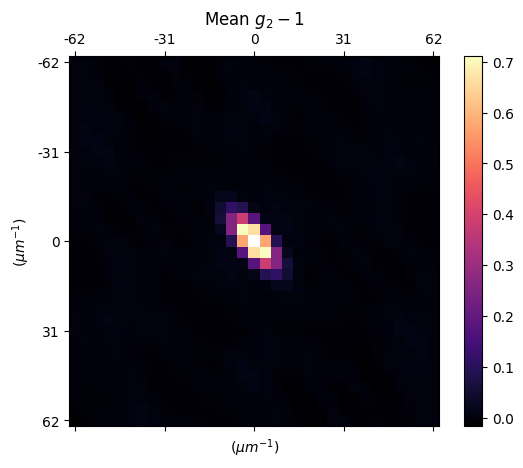

In [28]:
idi.util.plot_2d(
    correlator.mean - 1,
    mask_center=True,
    crop=(33, 33),
    E=E,
    detz=detector_distance * 1e4,
    pixelsize=pixelsize,
    title="Mean $g_2-1$",
    q_ticks=True,
);

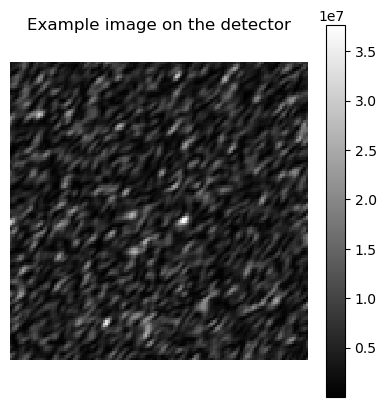

In [ ]:
if not isinstance(photons, np.ndarray):
    photons = photons.get()
plt.matshow(photons, cmap="gray")
plt.colorbar()
plt.axis("off")
plt.title("Example image on the detector");

In [26]:
import pandas as pd

ModuleNotFoundError: No module named 'pandas'

In [27]:
df = pd.read_csv("fit_data_idi.csv")

NameError: name 'pd' is not defined

In [ ]:
97, 110, -0.7

,Unnamed: 0,run,pannel,tile,zposition,sigmax,sigmay,beta,rho,centerx,...,sigmax_stderr,sigmay_stderr,beta_stderr,rho_stderr,centerx_stderr,centery_stderr,pulse_length_fs_stderr,FWHMx_nm_stderr,FWHMy_nm_stderr,correlation
128,128,98,0,lower,-3.247,1.118219e-07,1.688870e-07,0.064439,-0.291195,0,...,3.284023e-09,4.019281e-09,0.004557,0.021925,0,0,0.209030,7.733217,9.464604,<__main__.Correlation object at 0x7fbe2a56eca0>
129,129,98,0,upper,-3.247,1.605959e-07,1.521873e-07,0.041119,-0.597783,0,...,7.046866e-09,6.895762e-09,0.004222,0.036557,0,0,0.475579,16.593959,16.238141,<__main__.Correlation object at 0x7fbe2d09e5b0>
130,130,98,1,lower,-3.247,9.755505e-08,1.106418e-07,0.047767,-0.070729,0,...,2.161973e-09,2.366336e-09,0.002093,0.018466,0,0,0.174704,5.091015,5.572249,<__main__.Correlation object at 0x7fbe29e43430>
131,131,98,1,upper,-3.247,1.572757e-07,1.243388e-07,0.048636,-0.143789,0,...,6.147689e-09,5.837962e-09,0.006283,0.028265,0,0,0.505891,14.476577,13.747232,<__main__.Correlation object at 0x7fbe2d5dae20>
132,132,98,2,lower,-3.247,8.578766e-08,1.247327e-07,0.047591,0.258294,0,...,1.911241e-09,2.545774e-09,0.001957,0.019094,0,0,0.164542,4.500589,5.994790,<__main__.Correlation object at 0x7fbe2cc44c40>
133,133,98,2,upper,-3.247,1.438964e-07,1.237180e-07,0.048308,0.360243,0,...,4.553504e-09,4.259833e-09,0.004176,0.028187,0,0,0.340786,10.722590,10.031055,<__main__.Correlation object at 0x7fbe2cc22400>
134,134,98,3,lower,-3.247,8.198008e-08,1.689260e-07,0.039543,0.347438,0,...,2.569933e-09,4.569477e-09,0.002343,0.026237,0,0,0.285332,6.051678,10.760204,<__main__.Correlation object at 0x7fbe2a577400>
135,135,98,3,upper,-3.247,1.350847e-07,1.785800e-07,0.040540,0.677419,0,...,4.982258e-09,5.954000e-09,0.002659,0.026308,0,0,0.308155,11.732221,14.020479,<__main__.Correlation object at 0x7fbe2a588d00>
136,136,98,4,lower,-3.247,1.278063e-07,1.648048e-07,0.044144,0.561564,0,...,4.204685e-09,4.826464e-09,0.003125,0.027872,0,0,0.305432,9.901192,11.365359,<__main__.Correlation object at 0x7fbe2d5f3700>
137,137,98,4,upper,-3.247,8.567478e-08,1.769064e-07,0.047365,0.322303,0,...,2.592772e-09,4.599608e-09,0.002833,0.024609,0,0,0.240539,6.105460,10.831157,<__main__.Correlation object at 0x7fbe2a594220>


In [ ]:
idi.util.gaussian2d_principal(97, 110, -0.07)

(np.float64(110.87563036889001),
 np.float64(95.99788846793076),
 np.float64(-1.3174174861043741))

In [ ]:
(
    np.float64(110.87563036889001),
    np.float64(95.99788846793076),
    np.float64(-1.3174174861043741 / np.pi * 180),
)

(np.float64(110.87563036889001),
 np.float64(95.99788846793076),
 np.float64(-75.48246181051542))